# Лабораторна робота №4. AI-підкріплена дата-аналітика: побудова власного аналітичного асистента
Прототип аналітичного асистента на базі **Python (Pandas, Matplotlib)** та **Google Gemini API** для автоматизації EDA, генерації гіпотез, виконання запитів природною мовою, візуалізації та підготовки управлінських звітів на датасеті *Telco Customer Churn*.

### 1. Ініціалізація середовища, завантаження даних та підключення до Gemini API
Завантаження датасету *Telco Customer Churn* за прямим посиланням із GitHub, зчитування API-ключа з Colab Secrets та налаштування функції-обгортки `call_gemini()` із резервуванням моделей і примусовим поверненням JSON.

In [7]:
import json
import time
import pandas as pd
from google.colab import userdata
from google import genai
from google.genai import types

# 1. Завантаження датасету з GitHub
CSV_URL = "https://raw.githubusercontent.com/rshvtss/LR4_MIPA/refs/heads/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(CSV_URL)
print(f"Датасет успішно завантажено: {df.shape[0]} рядків, {df.shape[1]} колонок")

# 2. Підключення до Gemini API
api_key = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

# Список моделей за пріоритетом (якщо перша зайнята – беремо наступну)
MODELS = ["gemini-3.5-flash-lite", "gemini-2.5-flash-lite"]

def call_gemini(prompt: str, system_instruction: str = None, json_mode: bool = True) -> str:
    config = types.GenerateContentConfig(
        system_instruction=system_instruction,
        response_mime_type="application/json" if json_mode else "text/plain",
        temperature=0.0
    )
    last_error = None
    for model_name in MODELS:
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=prompt,
                config=config
            )
            return response.text
        except Exception as e:
            print(f"Модель {model_name} недоступна ({type(e).__name__}), пробуємо наступну...")
            last_error = e
            time.sleep(1)
    raise last_error

# 3. Тестовий виклик
test_raw = call_gemini("Поверни JSON з двома полями: status (значення 'ok') та rows (значення 7043).")
print("Відповідь моделі:", json.loads(test_raw))

Датасет успішно завантажено: 7043 рядків, 21 колонок
Відповідь моделі: {'status': 'ok', 'rows': 7043}


### 2. Функція 1 – Автоматичний первинний аналіз даних (`auto_eda`)
Програмний збір статистичного профілю таблиці через Pandas (типи даних, явні та приховані пропуски, дублікати, викиди за IQR) та генерація структурованого аудиту якості даних за допомогою LLM.

In [8]:
import numpy as np

# Системний промпт для auto_eda
EDA_SYSTEM_PROMPT = """
Ти – досвідчений продуктовий дата-аналітик. Твоє завдання – провести первинний аудит якості даних (EDA) на основі переданого JSON зі статистиками.

СУВОРІ ПРАВИЛА:
1. Використовуй ТІЛЬКИ ті числа, які є у вхідному JSON. Категорично заборонено вигадувати, округлювати до інших значень або дораховувати власні цифри.
2. Звертай особливу увагу на приховані проблеми: колонки типу 'object', де можуть бути числа (наприклад, через пробіли), дисбаланс класів, високу частку пропусків або викиди.
3. Відповідай українською мовою.
4. Поверни результат суворо у форматі JSON зі структурою:
{
  "dataset_overview": "короткий опис обсягу та структури даних (2-3 речення)",
  "data_quality_issues": ["список конкретних проблем із типами даних, пропусками чи дублікатами з точними цифрами"],
  "key_distributions": ["опис розподілів ключових числових та категоріальних ознак"],
  "cleaning_recommendations": ["конкретні кроки, що треба виправити перед подальшим аналізом"]
}
"""

def auto_eda(dataframe: pd.DataFrame) -> dict:
    # 1. Перевірка на порожній датафрейм (edge case)
    if dataframe is None or dataframe.empty:
        return {"error": "Датафрейм порожній. Аналіз неможливий."}

    # 2. Програмний розрахунок статистик через Pandas
    summary = {
        "rows": int(dataframe.shape[0]),
        "columns": int(dataframe.shape[1]),
        "duplicate_rows": int(dataframe.duplicated().sum()),
        "columns_info": {}
    }

    for col in dataframe.columns:
        col_data = dataframe[col]
        null_count = int(col_data.isnull().sum())
        # Перевірка на приховані пропуски (пробіли замість значень у текстових колонках)
        blank_count = int((col_data.astype(str).str.strip() == "").sum()) if col_data.dtype == "object" else 0

        col_stats = {
            "dtype": str(col_data.dtype),
            "null_count": null_count,
            "blank_strings_count": blank_count,
            "unique_values": int(col_data.nunique())
        }

        if pd.api.types.is_numeric_dtype(col_data):
            q1 = col_data.quantile(0.25)
            q3 = col_data.quantile(0.75)
            iqr = q3 - q1
            outliers = int(((col_data < (q1 - 1.5 * iqr)) | (col_data > (q3 + 1.5 * iqr))).sum())
            col_stats["stats"] = {
                "min": round(float(col_data.min()), 2),
                "median": round(float(col_data.median()), 2),
                "mean": round(float(col_data.mean()), 2),
                "max": round(float(col_data.max()), 2),
                "outliers_iqr": outliers
            }
        else:
            top_values = col_data.value_counts().head(3).to_dict()
            col_stats["top_3_values"] = {str(k): int(v) for k, v in top_values.items()}

        summary["columns_info"][col] = col_stats

    # 3. Передача агрегованого JSON у LLM для інтерпретації
    user_prompt = f"Проаналізуй ці статистики датасету та сформуй EDA-звіт:\n{json.dumps(summary, ensure_ascii=False)}"
    raw_response = call_gemini(prompt=user_prompt, system_instruction=EDA_SYSTEM_PROMPT, json_mode=True)

    return json.loads(raw_response)

# Тестовий запуск на нашому датасеті
eda_report = auto_eda(df)
print(json.dumps(eda_report, indent=2, ensure_ascii=False))

{
  "dataset_overview": "Датасет містить 7043 рядки та 21 колонку. Повністю відсутні дублікати рядків (duplicate_rows: 0), а явні нульові значення (null_count) у всіх колонках дорівнюють 0.",
  "data_quality_issues": [
    "Колонка 'TotalCharges' має тип даних 'object', хоча містить числові дані, і в ній виявлено 11 порожніх рядків (blank_strings_count), які заповнені пробілами (' ' : 11).",
    "Колонка 'SeniorCitizen' має тип int64, але містить 1142 викиди (outliers_iqr), що обумовлено її бінарною природою (значення 0 та 1)."
  ],
  "key_distributions": [
    "Розподіл 'gender' є майже збалансованим між чоловіками (3555) та жінками (3488).",
    "Для колонки 'tenure' мінімальне значення становить 0.0, медіана — 29.0, середнє — 32.37, а максимальне — 72.0 при 0 викидах за методом IQR.",
    "Для колонки 'MonthlyCharges' мінімальне значення становить 18.25, медіана — 70.35, середнє — 64.76, а максимальне — 118.75.",
    "Цільова змінна 'Churn' має дисбаклас класів: 5174 значення 'No' п

### 3. Очистка даних та Функція 2 – Генерація продуктових гіпотез (`suggest_hypotheses`)
Конвертація колонки `TotalCharges` у числовий формат, розрахунок базового рівня відтоку (`Churn`) і сегментованих метрик через `groupby`, формулювання 8 обґрунтованих бізнес-гіпотез на основі точних цифр.

In [9]:
# Попередня підготовка даних на основі висновків auto_eda
df_clean = df.copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0.0)

HYPOTHESES_SYSTEM_PROMPT = """
Ти – старший продуктовий аналітик. На основі переданих агрегованих даних про відтік клієнтів (Churn) сформулюй 6–8 конкретних бізнес-гіпотез.

СУВОРІ ПРАВИЛА:
1. Кожна гіпотеза МАЄ спиратися на точні цифри з вхідного JSON (порівняння з базовим рівнем відтоку або між сегментами). Заборонено вигадувати числа.
2. Не пиши загальних фраз на кшталт «треба покращити сервіс». Вказуй конкретний сегмент, його розмір, метрику та ймовірну причину поведінки користувачів.
3. Відповідай українською мовою.
4. Поверни результат суворо у форматі JSON зі структурою:
{
  "baseline_metric": "коротке формулювання базового показника по всьому датасету",
  "hypotheses": [
    {
      "id": 1,
      "segment": "назва ознаки та сегмента",
      "evidence": "точні цифри з даних (розмір групи, відсоток відтоку, порівняння з нормою)",
      "hypothesis": "формулювання гіпотези: чому так відбувається",
      "suggested_action": "що конкретно варто перевірити або протестувати продукту/маркетингу"
    }
  ]
}
"""

def suggest_hypotheses(dataframe: pd.DataFrame, target_col: str = "Churn") -> dict:
    if dataframe is None or dataframe.empty:
        return {"error": "Датафрейм порожній."}
    if target_col not in dataframe.columns:
        return {"error": f"Цільова колонка '{target_col}' відсутня у даних."}

    temp_df = dataframe.copy()
    # Перетворюємо Churn ('Yes'/'No') у числовий прапорець 1/0 для зручного розрахунку часток
    temp_df["is_churn"] = (temp_df[target_col] == "Yes").astype(int)

    baseline_rate = round(float(temp_df["is_churn"].mean() * 100), 2)

    analysis_payload = {
        "total_customers": int(len(temp_df)),
        "baseline_churn_rate_pct": baseline_rate,
        "categorical_segments": {},
        "numeric_comparison_by_churn": {}
    }

    # 1. Агрегація по категоріальних ознаках (ігноруємо ID та сам таргет)
    cat_cols = [c for c in temp_df.select_dtypes(include=["object"]).columns if c not in ["customerID", target_col]]
    for col in cat_cols:
        grouped = temp_df.groupby(col)["is_churn"].agg(
            customers_count="count",
            churn_rate_pct=lambda x: round(float(x.mean() * 100), 2)
        ).reset_index()
        analysis_payload["categorical_segments"][col] = grouped.to_dict(orient="records")

    # 2. Порівняння числових метрик між тими, хто пішов, і тими, хто залишився
    num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
    for col in num_cols:
        if col in temp_df.columns:
            num_grouped = temp_df.groupby(target_col)[col].agg(
                mean=lambda x: round(float(x.mean()), 2),
                median=lambda x: round(float(x.median()), 2)
            ).to_dict(orient="index")
            analysis_payload["numeric_comparison_by_churn"][col] = num_grouped

    user_prompt = f"Згенеруй продуктово-аналітичні гіпотези на основі цих розрахунків:\n{json.dumps(analysis_payload, ensure_ascii=False)}"
    raw_response = call_gemini(prompt=user_prompt, system_instruction=HYPOTHESES_SYSTEM_PROMPT, json_mode=True)

    return json.loads(raw_response)

# Тестовий запуск
hypotheses_report = suggest_hypotheses(df_clean)
print(json.dumps(hypotheses_report, indent=2, ensure_ascii=False))

{
  "baseline_metric": "Базовий рівень відтоку (Baseline Churn Rate) по всьому датасету складає 26.54% для 7043 клієнтів",
  "hypotheses": [
    {
      "id": 1,
      "segment": "Contract: Month-to-month",
      "evidence": "Група налічує 3875 клієнтів (найбільший сегмент за контрактами), рівень відтоку становить 42.71%, що суттєво перевищує базовий рівень 26.54% та показники річних контрактів (11.27%) і дворічних (2.83%)",
      "hypothesis": "Клієнти без довгострокових зобов'язань легко приймають рішення про відмову від послуг через відсутність фінансової мотивації або стримуючих факторів (штрафів за достроковий розрив)",
      "suggested_action": "Розробити програму лояльності або знижки при переході з місячної оплати на річні контракти (One/Two year)"
    },
    {
      "id": 2,
      "segment": "InternetService: Fiber optic",
      "evidence": "Сегмент налічує 3096 клієнтів з високим рівнем відтоку 41.89%, що в рази вище показників DSL (18.96%), відсутності інтернету (7.4%) та ба

### 4. Функція 3 – Natural Language to Pandas (`ask_data`)
Перетворення запитів природною мовою у виконуваний Pandas-код із урахуванням схеми даних, виведення коду для перевірки аналітиком, ізольоване виконання та фільтрація нерелевантних запитів.

In [10]:
NL2PANDAS_SYSTEM_PROMPT = """
Ти – Python Data Analyst. Твоє завдання – перетворити запит користувача природною мовою у виконуваний код на бібліотеці Pandas.

ПРАВИЛА ГЕНЕРАЦІЇ КОДУ:
1. Датафрейм вже завантажений у змінну `df`, бібліотека pandas імпортована як `pd`. Не пиши `pd.read_csv()` чи `import pandas`.
2. Використовуй ТІЛЬКИ ті назви колонок і точні значення категорій, які передані у схемі датафрейму.
3. Фінальний результат обчислень обов'язково збережи у змінну `result` (це може бути число, рядок, Series або DataFrame).
4. Не використовуй `print()` всередині згенерованого коду, просто запиши відповідь у `result`.
5. Якщо запит не стосується даних у таблиці, вимагає неіснуючих колонок або є нелогічним (наприклад, питання про погоду, курс валют, дати, яких немає в таблиці), встанови `is_valid: false` та поясни причину.
6. Поверни відповідь суворо у форматі JSON:
{
  "is_valid": true або false,
  "explanation": "коротке пояснення українською, що саме робить код або чому запит неможливо виконати",
  "python_code": "рядок із чистим Python-кодом без markdown-обгорток ```python"
}
"""

def _get_df_schema(dataframe: pd.DataFrame) -> dict:
    """Допоміжна функція для збору схеми датафрейму та унікальних значень категорій."""
    schema = {}
    for col in dataframe.columns:
        dtype_str = str(dataframe[col].dtype)
        if dataframe[col].nunique() <= 10:
            schema[col] = {
                "dtype": dtype_str,
                "unique_values": [str(v) for v in dataframe[col].unique()]
            }
        else:
            schema[col] = {
                "dtype": dtype_str,
                "example_values": [str(v) for v in dataframe[col].dropna().head(3).tolist()]
            }
    return schema

def ask_data(dataframe: pd.DataFrame, query: str):
    if dataframe is None or dataframe.empty:
        print("Помилка: датафрейм порожній.")
        return None

    schema = _get_df_schema(dataframe)
    user_prompt = (
        f"Схема датафрейму `df`:\n{json.dumps(schema, ensure_ascii=False)}\n\n"
        f"Запит користувача: {query}"
    )

    raw_response = call_gemini(prompt=user_prompt, system_instruction=NL2PANDAS_SYSTEM_PROMPT, json_mode=True)
    parsed = json.loads(raw_response)

    print(f"Запит: {query}")
    print(f"Логіка: {parsed.get('explanation')}")

    if not parsed.get("is_valid"):
        print("Результат: Запит відхилено як нерелевантний до структури даних.\n" + "-" * 60)
        return None

    code = parsed.get("python_code", "").strip()
    print("\n--- Згенерований Pandas-код ---")
    print(code)
    print("-------------------------------")

    # Ізольоване середовище для виконання коду
    local_env = {"df": dataframe.copy(), "pd": pd, "result": None}
    try:
        exec(code, {"__builtins__": {}}, local_env)
        result = local_env["result"]
        print("Результат виконання:")
        display(result) if isinstance(result, (pd.DataFrame, pd.Series)) else print(result)
        print("-" * 60)
        return result
    except Exception as e:
        print(f"Помилка під час виконання коду: {type(e).__name__}: {e}")
        print("-" * 60)
        return None

# Тестуємо на 3 різних запитах (звичайний, з групуванням та нелогічний)
ask_data(df_clean, "Який середній та медіанний MonthlyCharges у клієнтів із Fiber optic, які пішли у відтік?")
ask_data(df_clean, "Виведи таблицю по кожному типу контракту: кількість клієнтів, середній tenure та суму TotalCharges.")
ask_data(df_clean, "Яка температура повітря сьогодні в Києві і як вона впливає на Churn?")

Запит: Який середній та медіанний MonthlyCharges у клієнтів із Fiber optic, які пішли у відтік?
Логіка: Обчислення середнього та медіанного значення щомісячних витрат (MonthlyCharges) для клієнтів, які користуються інтернетом 'Fiber optic' та пішли у відтік (Churn == 'Yes').

--- Згенерований Pandas-код ---
filtered_df = df[(df['InternetService'] == 'Fiber optic') & (df['Churn'] == 'Yes')]; result = {'mean': filtered_df['MonthlyCharges'].mean(), 'median': filtered_df['MonthlyCharges'].median()}
-------------------------------
Результат виконання:
{'mean': np.float64(88.12648419429453), 'median': 87.55}
------------------------------------------------------------
Запит: Виведи таблицю по кожному типу контракту: кількість клієнтів, середній tenure та суму TotalCharges.
Логіка: Групує дані за колонкою Contract та обчислює кількість клієнтів (count для customerID), середній tenure та суму TotalCharges для кожного типу контракту.

--- Згенерований Pandas-код ---
result = df.groupby('Contrac

,count,tenure,TotalCharges
Contract,,,
Month-to-month,3875,18.036645,5305861.5
One year,1473,42.044807,4467053.5
Two year,1695,56.735103,6283253.7


------------------------------------------------------------
Запит: Яка температура повітря сьогодні в Києві і як вона впливає на Churn?
Логіка: Запит стосується температури повітря в Києві, проте в наданій схемі датафрейму відсутні дані про погоду чи географічне положення клієнтів.
Результат: Запит відхилено як нерелевантний до структури даних.
------------------------------------------------------------


### 5. Тестування крайніх випадків (Edge Cases)
Перевірка стійкості асистента до некоректних вхідних даних: передача порожнього `DataFrame` у функції аналізу та звернення до неіснуючих колонок у модулі `ask_data`.

In [11]:
# Блок тестування крайніх випадків (Edge Cases)
print("=== ТЕСТ 1: Порожній датафрейм у auto_eda та suggest_hypotheses ===")
empty_df = pd.DataFrame()
print("auto_eda(empty_df):", auto_eda(empty_df))
print("suggest_hypotheses(empty_df):", suggest_hypotheses(empty_df))

print("\n=== ТЕСТ 2: Запит до неіснуючої колонки у ask_data ===")
ask_data(df_clean, "Порахуй середній вік клієнтів (колонка Age) та їхній кредитний рейтинг.")

=== ТЕСТ 1: Порожній датафрейм у auto_eda та suggest_hypotheses ===
auto_eda(empty_df): {'error': 'Датафрейм порожній. Аналіз неможливий.'}
suggest_hypotheses(empty_df): {'error': 'Датафрейм порожній.'}

=== ТЕСТ 2: Запит до неіснуючої колонки у ask_data ===
Запит: Порахуй середній вік клієнтів (колонка Age) та їхній кредитний рейтинг.
Логіка: У схемі датафрейму відсутні колонки Age (вік) та кредитний рейтинг.
Результат: Запит відхилено як нерелевантний до структури даних.
------------------------------------------------------------


### 6. Функція 4 – Генерація управлінського звіту (`generate_executive_summary`)
Розрахунок фінансових втрат від відтоку (Monthly Revenue at Risk) та формування стислого бізнес-орієнтованого резюме для керівництва з пріоритетними кроками.

In [12]:
EXEC_SUMMARY_SYSTEM_PROMPT = """
Ти – Head of Data Analytics, який готує короткий звіт (Executive Summary) для СЕО та продуктового директора.
Твоє завдання – на основі переданих фінансових KPI та знайдених гіпотез сформувати стислий бізнес-орієнтований документ.

СУВОРІ ПРАВИЛА:
1. Оперуй ТІЛЬКИ переданими цифрами. Не вигадуй нових показників чи відсотків.
2. Пиши діловою, конкретною мовою без загальних фраз. Фокусуйся на грошах (втрачена виручка) та пріоритетах дій.
3. Відповідай українською мовою.
4. Поверни результат суворо у форматі JSON зі структурою:
{
  "headline": "одне речення-висновок про головну проблему бізнесу з ключовою цифрою",
  "what_happened": "короткий опис поточної ситуації з клієнтською базою, відтоком та фінансовими втратами (3-4 речення)",
  "why_it_matters": "пояснення впливу на бізнес-метрики (LTV, стабільність виручки) та опис найризиковіших сегментів",
  "next_steps": [
    "Пріоритет 1: конкретна дія з очікуваним ефектом",
    "Пріоритет 2: конкретна дія з очікуваним ефектом",
    "Пріоритет 3: конкретна дія з очікуваним ефектом"
  ]
}
"""

def generate_executive_summary(dataframe: pd.DataFrame, hypotheses_data: dict = None) -> dict:
    if dataframe is None or dataframe.empty:
        return {"error": "Датафрейм порожній."}

    churned = dataframe[dataframe["Churn"] == "Yes"]
    retained = dataframe[dataframe["Churn"] == "No"]

    total_monthly_rev = round(float(dataframe["MonthlyCharges"].sum()), 2)
    lost_monthly_rev = round(float(churned["MonthlyCharges"].sum()), 2)
    lost_rev_share = round((lost_monthly_rev / total_monthly_rev) * 100, 2) if total_monthly_rev > 0 else 0.0

    kpi_payload = {
        "total_customers": int(len(dataframe)),
        "churned_customers": int(len(churned)),
        "churn_rate_pct": round((len(churned) / len(dataframe)) * 100, 2),
        "total_monthly_revenue_usd": total_monthly_rev,
        "monthly_revenue_lost_to_churn_usd": lost_monthly_rev,
        "lost_revenue_share_pct": lost_rev_share,
        "avg_monthly_bill_churned_usd": round(float(churned["MonthlyCharges"].mean()), 2),
        "avg_monthly_bill_retained_usd": round(float(retained["MonthlyCharges"].mean()), 2),
        "top_hypotheses_summary": [
            {"segment": h["segment"], "evidence": h["evidence"], "action": h["suggested_action"]}
            for h in (hypotheses_data.get("hypotheses", [])[:4] if hypotheses_data else [])
        ]
    }

    user_prompt = f"Сформуй Executive Summary для керівництва на основі цих даних:\n{json.dumps(kpi_payload, ensure_ascii=False)}"
    raw_response = call_gemini(prompt=user_prompt, system_instruction=EXEC_SUMMARY_SYSTEM_PROMPT, json_mode=True)

    return json.loads(raw_response)

# Тестовий запуск
exec_summary = generate_executive_summary(df_clean, hypotheses_report)
print(json.dumps(exec_summary, indent=2, ensure_ascii=False))

{
  "headline": "Компанія втрачає $139,130.85 щомісяця через відтік 26.54% клієнтської бази, що становить 30.5% від загальної виручки.",
  "what_happened": "Із загальної бази у 7043 клієнти компанія втратила 1869 користувачів із середнім місячним чеком $74.44, який вище за показник утриманих клієнтів ($61.27). Загальна місячна виручка наразі становить $456,116.6, при цьому втрати від відтоку сягають $139,130.85 щомісяця. Найвищий відтік зафіксовано в сегментах із щомісячними контрактами (42.71%), інтернетом Fiber optic (41.89%), оплатою електронним чеком (45.29%) та відсутністю техпідтримки (41.64%).",
  "why_ip_matters": "Такий високий рівень відтоку критично знижує LTV клієнтів та підриває стабільність майбутньої виручки, оскільки йдуть користувачі з вищим чеком. Найбільшими зонами ризику є клієнти на місячних контрактах (3875 осіб), користувачі Fiber optic (3096 осіб) та клієнти без технічної підтримки (3473 особи), які генерують диспропорційні фінансові втрати.",
  "next_steps": [


### 7. Функція 5 – Візуалізація даних за запитом (`visualize_data`)
Генерація Python-коду на базі `matplotlib` за текстовим запитом користувача, виведення коду та побудова графіків розподілу відтоку і щомісячних платежів.

Запит на графік: Побудуй стовпчикову діаграму відсотка відтоку (Churn == 'Yes') для кожного типу контракту (Contract).
Опис: Стовпчикова діаграма показує відсоток відтоку клієнтів (Churn == 'Yes') для кожного типу контракту.

--- Згенерований код візуалізації ---
churn_by_contract = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(churn_by_contract['Contract'], churn_by_contract['Churn'], color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_title('Відсоток відтоку за типами контрактів')
ax.set_xlabel('Тип контракту')
ax.set_ylabel('Відтік (%)')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}%', ha='center', va='bottom')
ax.set_ylim(0, max(churn_by_contract['Churn']) * 1.15)
-------------------------------------


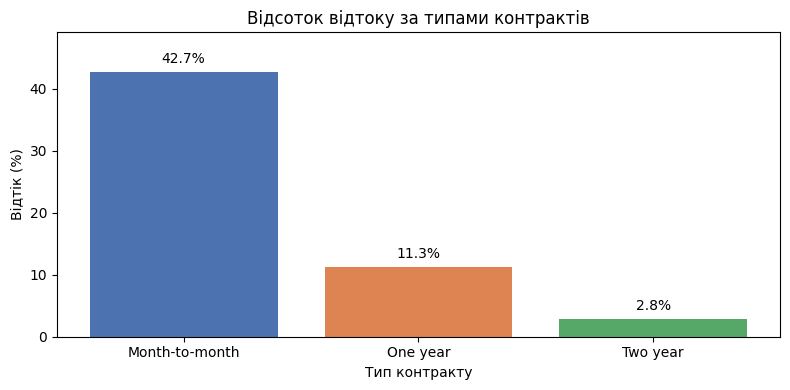

------------------------------------------------------------
Запит на графік: Порівняй розподіл MonthlyCharges для клієнтів з Churn 'Yes' та 'No' за допомогою boxplot.
Опис: На графіку зображено розподіл щомісячних платежів (MonthlyCharges) для клієнтів залежно від відтоку (Churn) за допомогою boxplot.

--- Згенерований код візуалізації ---
fig, ax = plt.subplots(figsize=(8, 4)); df.boxplot(column='MonthlyCharges', by='Churn', ax=ax, grid=False); ax.set_title('Розподіл MonthlyCharges за статусом Churn'); ax.set_xlabel('Churn'); ax.set_ylabel('Monthly Charges'); plt.suptitle('')
-------------------------------------


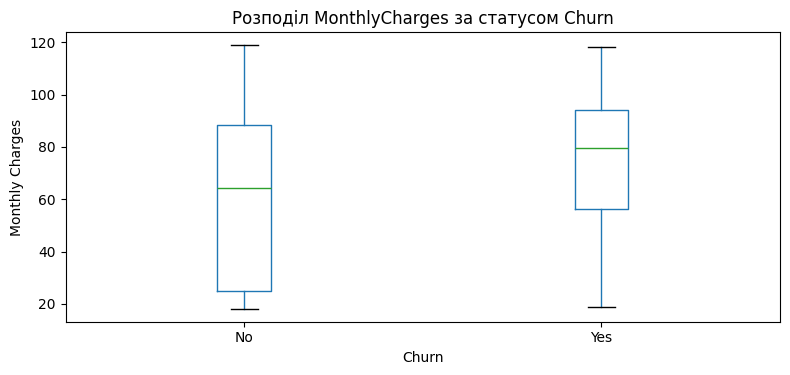

------------------------------------------------------------


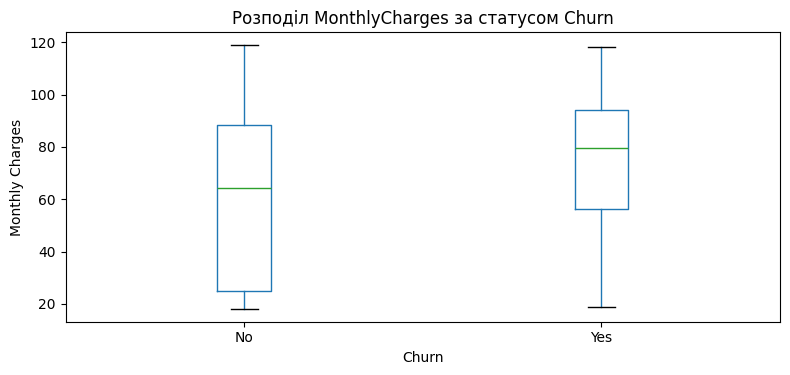

In [16]:
import matplotlib.pyplot as plt

VISUALIZE_SYSTEM_PROMPT = """
Ти – Data Visualization Engineer. Твоє завдання – написати Python-код на базі `pandas` та `matplotlib.pyplot` (імпортовано як `plt`) для побудови графіка за запитом користувача.

ПРАВИЛА:
1. Датафрейм вже завантажений у змінну `df`. Не пиши імпорти та не завантажуй файли.
2. Використовуй ТІЛЬКИ реальні колонки та категорії зі схеми датафрейму.
3. Створи фігуру через `fig, ax = plt.subplots(figsize=(8, 4))`, побудуй графік на `ax`, обов'язково додай заголовок (`ax.set_title`), підписи осей (`ax.set_xlabel`, `ax.set_ylabel`) та значення на стовпчиках, якщо це bar chart.
4. Не викликай `plt.show()`. Готовий об'єкт фігури має залишитися у змінній `fig`.
5. Якщо графік побудувати неможливо (неіснуючі колонки чи нелогічний запит), встанови `is_valid: false`.
6. Поверни відповідь суворо у форматі JSON:
{
  "is_valid": true або false,
  "explanation": "коротке пояснення українською, що зображено на графіку",
  "python_code": "чистий Python-код без markdown-обгорток"
}
"""

def visualize_data(dataframe: pd.DataFrame, query: str):
    if dataframe is None or dataframe.empty:
        print("Помилка: датафрейм порожній.")
        return None

    schema = _get_df_schema(dataframe)
    user_prompt = (
        f"Схема датафрейму `df`:\n{json.dumps(schema, ensure_ascii=False)}\n\n"
        f"Запит на візуалізацію: {query}"
    )

    raw_response = call_gemini(prompt=user_prompt, system_instruction=VISUALIZE_SYSTEM_PROMPT, json_mode=True)
    parsed = json.loads(raw_response)

    print(f"Запит на графік: {query}")
    print(f"Опис: {parsed.get('explanation')}")

    if not parsed.get("is_valid"):
        print("Результат: Неможливо побудувати графік за цим запитом.\n" + "-" * 60)
        return None

    code = parsed.get("python_code", "").strip()
    print("\n--- Згенерований код візуалізації ---")
    print(code)
    print("-------------------------------------")

    safe_builtins = {
        "max": max,
        "min": min,
        "len": len,
        "round": round,
        "sum": sum,
        "range": range,
        "sorted": sorted,
        "abs": abs,
        "enumerate": enumerate,
        "zip": zip
    }
    local_env = {"df": dataframe.copy(), "pd": pd, "plt": plt, "fig": None}

    try:
        exec(code, {"__builtins__": safe_builtins}, local_env)
        fig = local_env["fig"]
        if fig is not None:
            plt.tight_layout()
            plt.show()
        print("-" * 60)
        return fig
    except Exception as e:
        print(f"Помилка побудови графіка: {type(e).__name__}: {e}")
        print("-" * 60)
        return None

# Тестуємо побудову 2 графіків
visualize_data(df_clean, "Побудуй стовпчикову діаграму відсотка відтоку (Churn == 'Yes') для кожного типу контракту (Contract).")
visualize_data(df_clean, "Порівняй розподіл MonthlyCharges для клієнтів з Churn 'Yes' та 'No' за допомогою boxplot.")